## Engineered EEG features

In [ ]:
from google.colab import files
import io
import zipfile
import os
import time

uploaded = files.upload()

# Get the uploaded file's name
uploaded_file_name = list(uploaded.keys())[0]

# Read the uploaded file into memory
zip_data = io.BytesIO(uploaded[uploaded_file_name])

extract_path = "eeg_dataset"

# Extract the zip file
with zipfile.ZipFile(zip_data, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# Verify extraction
print("Extracted files:")
print(os.listdir(extract_path))

Saving archive.zip to archive.zip
Extracted files:
['New folder']


In [ ]:
#Loading single channel csv file be funny data emotion
import pandas as pd

sample_file = os.path.join(extract_path, "New folder/Commercial _advertisemnets/Ch1_ads_all_classes/Funny_data_Ch1.csv")

# Load CSV without header
df = pd.read_csv(sample_file, header=None)

# Display the first few rows
print(df.head())


       0       1       2       3       4       5       6        7       8   \
0  7.0953  10.254  11.963 -21.530 -1.2817  4.0436 -1.3580 -12.8630  9.7351   
1  7.0801  10.467  11.856 -21.240 -1.4191  3.0365 -2.2278 -11.7640  8.9569   
2  6.9733  10.635  11.749 -20.966 -1.5717  3.0365 -3.0060 -10.4060  7.9498   
3  7.8430  10.742  11.643 -20.721 -1.7242  2.3193 -3.5706  -8.8654  6.8359   
4  8.6517  10.819  11.505 -20.508 -1.8768  2.1362 -3.7842  -7.2174  5.8594   

       9   ...       12      13       14      15       16      17      18  \
0 -2.7924  ...  0.91553  4.8981  -9.6283 -3.4485 -0.67139  13.779  4.3793   
1 -2.7618  ...  1.17490  5.9051  -9.8572 -3.4027 -0.62561  14.832  4.6082   
2 -3.1891  ...  1.43430  6.8817 -10.0860 -3.3722 -0.56458  15.900  4.8218   
3 -3.9825  ...  1.69370  7.8125 -10.3000 -3.3417 -0.51880  16.998  5.0354   
4 -4.9591  ...  1.92260  8.6670 -10.4830 -3.3112 -0.47302  18.112  5.2490   

       19      20      21  
0  1.8921 -4.7302  4.1046  
1  1.9989 -4

In [ ]:
#Load Multi-Channel CSV Files by Emotion
import pandas as pd
import numpy as np
import glob

# Map each emotion to a label
emotion_labels = {
    "Funny": 0,
    "Sad": 1,
    "Scary": 2,
    "Relaxed": 3,
    "Enjoyed": 4
}

# Base path
base_folder = extract_path + "/New folder"

# Collect files
all_files = glob.glob(base_folder + "/**/*.csv", recursive=True)

# Organize by emotion
emotion_data = {emotion: [] for emotion in emotion_labels.keys()}

for file_path in all_files:
    for emotion in emotion_labels:
        if emotion.lower() in file_path.lower():
            emotion_data[emotion].append(file_path)


In [ ]:
#Extract Time & Frequency Features
from scipy.fft import fft

def extract_features(df):
    features = []

    for col in df.columns:
        signal = df[col].values

        # Time domain features
        stats = [np.mean(signal), np.std(signal), np.min(signal), np.max(signal)]

        # Frequency domain (FFT)
        fft_vals = np.abs(fft(signal))
        freqs = np.fft.fftfreq(len(signal))

        # Extract band powers (simplified)
        fft_mean = np.mean(fft_vals)
        fft_std = np.std(fft_vals)

        stats += [fft_mean, fft_std]
        features.extend(stats)

    return features


In [ ]:
# Build the Dataset from All Files
X = []
y = []

for emotion, files in emotion_data.items():
    for file in files:
        try:
            df = pd.read_csv(file, header=None)
            feats = extract_features(df)
            X.append(feats)
            y.append(emotion_labels[emotion])
        except Exception as e:
            print(f"Error loading {file}: {e}")

X = pd.DataFrame(X)
y = pd.Series(y)
print(f"Dataset shape: {X.shape}, Labels: {len(y)}")


Dataset shape: (12, 144), Labels: 12


In [ ]:
#Train and Evaluate a Random Forest Model from sklearn (ML Model)
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train model
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)

# Results
print("Accuracy:", accuracy_score(y_test, y_pred))

# Get unique labels from y_test and y_pred
unique_labels = sorted(set(y_test) | set(y_pred))
# Get target names for the unique labels
target_names = [emotion for emotion, label in emotion_labels.items() if label in unique_labels]

print(classification_report(y_test, y_pred, target_names=target_names))

Accuracy: 0.0
              precision    recall  f1-score   support

       Funny       0.00      0.00      0.00       1.0
         Sad       0.00      0.00      0.00       0.0
     Relaxed       0.00      0.00      0.00       1.0
     Enjoyed       0.00      0.00      0.00       1.0

    accuracy                           0.00       3.0
   macro avg       0.00      0.00      0.00       3.0
weighted avg       0.00      0.00      0.00       3.0



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_

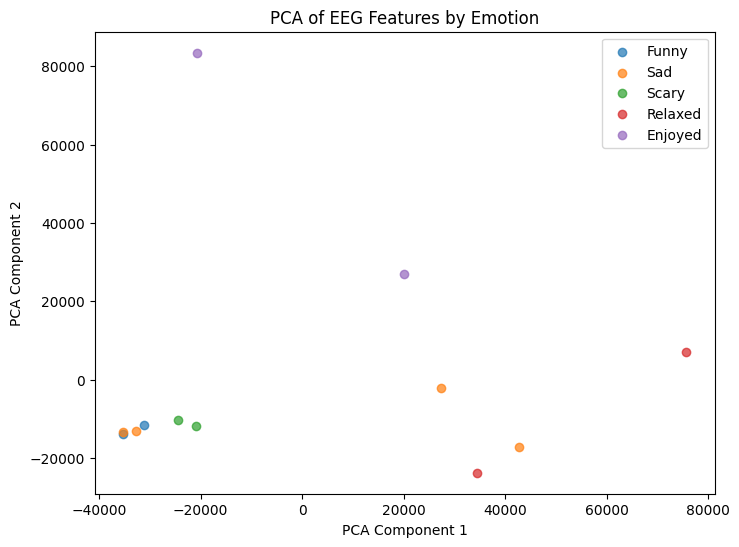

In [ ]:
# PCA Visualization of Emotion Clusters with the help of deep learning
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce dimensions to 2D
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Plot
plt.figure(figsize=(8, 6))
for label in np.unique(y):
    plt.scatter(
        X_pca[y == label, 0],
        X_pca[y == label, 1],
        label=[k for k, v in emotion_labels.items() if v == label][0],
        alpha=0.7
    )
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("PCA of EEG Features by Emotion")
plt.legend()
plt.show()


In [ ]:
!pip install -q tensorflow


In [ ]:
#Train a Simple Neural Network
import numpy as np
from sklearn.model_selection import train_test_split

# Convert DataFrame to NumPy array
X_array = X
y_array = y.to_numpy()

# Normalize features for better neural network performance
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_array)

# Split into training and testing
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_array, test_size=0.2, random_state=42)

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Define the model architecture
model = models.Sequential([
    layers.Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dense(len(np.unique(y_array)), activation='softmax')  # Output neurons = number of emotion classes
])


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


In [ ]:
# Train the Nueral network Model

history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=8,
    verbose=1
)


Epoch 1/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.1429 - loss: 2.3460 - val_accuracy: 0.0000e+00 - val_loss: 2.0862
Epoch 2/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.1429 - loss: 1.9117 - val_accuracy: 0.0000e+00 - val_loss: 1.9544
Epoch 3/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - accuracy: 0.4286 - loss: 1.4436 - val_accuracy: 0.0000e+00 - val_loss: 1.8320
Epoch 4/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 0.2857 - loss: 1.3219 - val_accuracy: 0.0000e+00 - val_loss: 1.7179
Epoch 5/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.5714 - loss: 1.1086 - val_accuracy: 0.0000e+00 - val_loss: 1.6131
Epoch 6/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.7143 - loss: 0.9155 - val_accuracy: 0.0000e+00 - val_loss: 1.5140
Epoch 7/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.7143 - loss: 0.8086 - val_accuracy: 0.0000e+00 - val_loss: 1.4211
Epoch 8/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.8571 - loss: 0.6965 - val_accura

In [ ]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {accuracy:.2f}")


Test Accuracy: 0.33


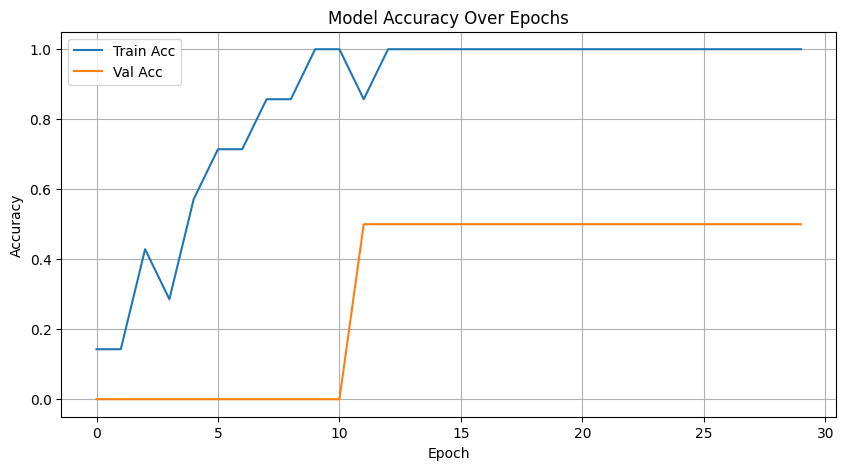

In [ ]:
#shows the training hstory using plot
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title("Model Accuracy Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
Shape of y_test: (2,)
Shape of y_pred_classes: (2,)


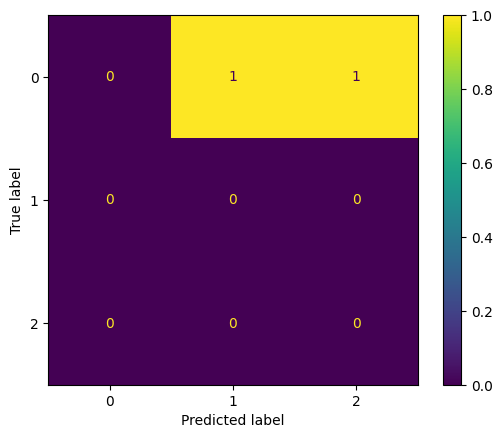

In [ ]:
#Confusion matrix ti identify if the model correctly or incorrectly classifies each emotion.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict on the test data using the trained model
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)

# Ensure y_test and y_pred_classes have the same length
min_len = min(len(y_test), len(y_pred_classes))
y_test = y_test[:min_len]
y_pred_classes = y_pred_classes[:min_len]

# Before calling confusion_matrix, print the shapes:
print("Shape of y_test:", y_test.shape)
print("Shape of y_pred_classes:", y_pred_classes.shape)

cm = confusion_matrix(y_test, y_pred_classes)
ConfusionMatrixDisplay(cm).plot()

#  Raw EEG time-series data using a 1D Convolutional Neural Network (CNN)


In [ ]:
import pandas as pd
import numpy as np

# Example: Load one file from each emotion
file_paths = {
    "Funny": emotion_data["Funny"][0],
    "Sad": emotion_data["Sad"][0],
    "Scary": emotion_data["Scary"][0]
}

# Load and stack as a time series
X_raw = []
y_raw = []

for label, path in file_paths.items():
    df = pd.read_csv(path, header=None)

    data = df.T.values  # Shape: (channels, timesteps)
    X_raw.append(data)
    y_raw.append(emotion_labels[label])

X_raw = np.array(X_raw)           # Shape: (samples, channels, timesteps)
X_raw = np.transpose(X_raw, (0, 2, 1))  # → (samples, timesteps, channels)
y_raw = np.array(y_raw)

print("Shape of raw EEG input:", X_raw.shape)


Shape of raw EEG input: (3, 20000, 22)


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

model_raw = models.Sequential([
    layers.Conv1D(64, kernel_size=3, activation='relu', input_shape=(X_raw.shape[1], X_raw.shape[2])),
    layers.MaxPooling1D(pool_size=2),
    layers.Conv1D(128, kernel_size=3, activation='relu'),
    layers.GlobalAveragePooling1D(),
    layers.Dense(64, activation='relu'),
    layers.Dense(len(np.unique(y_raw)), activation='softmax')
])


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model_raw.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_raw.fit(X_raw, y_raw, epochs=20, batch_size=1, validation_split=0.2)


Epoch 1/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 553ms/step - accuracy: 1.0000 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch 2/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 314ms/step - accuracy: 0.6667 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch 3/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step - accuracy: 0.3333 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch 4/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.6667 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch 5/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.3333 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch 6/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.3333 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch 7/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step - accuracy: 0.3333 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch 8/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 241ms/step - accuracy: 0.6667 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch 9/

In [ ]:
loss, acc = model_raw.evaluate(X_raw, y_raw, verbose=0)
print(f"Accuracy on raw EEG: {acc:.2f}")


Accuracy on raw EEG: 0.33


In [ ]:
import pandas as pd
import numpy as np

X_raw = []
y_raw = []
shapes = []

for emotion, files in emotion_data.items():
    for file in files:
        try:
            df = pd.read_csv(file, header=None)
            data = df.T.values  # shape: (channels, timesteps)
            data = data.T       # shape: (timesteps, channels)
            X_raw.append(data)
            y_raw.append(emotion_labels[emotion])
            shapes.append(data.shape)  # Append the shape of each file
        except Exception as e:
            print(f"Skipped file {file}: {e}")

# Check if shapes are consistent
if len(set(shapes)) != 1:
    print(" Inconsistent data shapes detected! Cannot create a uniform NumPy array.")
    print("Shapes of the data:", shapes)

    # Filter X_raw and y_raw based on the most common shape
    most_common_shape = max(set(shapes), key=shapes.count)
    X_raw = [x for i, x in enumerate(X_raw) if shapes[i] == most_common_shape]
    y_raw = [y for i, y in enumerate(y_raw) if shapes[i] == most_common_shape]

    # Convert to NumPy arrays
    X_raw = np.array(X_raw)
    y_raw = np.array(y_raw)

else:
    # Convert to numpy arrays if shapes are consistent
    X_raw = np.array(X_raw)
    y_raw = np.array(y_raw)

print(" Dataset shape:", X_raw.shape)
print(" Labels shape:", y_raw.shape)

# Reshape X_raw to have shape (num_samples, timesteps * channels)
num_samples = X_raw.shape[0]
timesteps = X_raw.shape[1]
channels = X_raw.shape[2]
X_raw_reshaped = X_raw.reshape(num_samples, timesteps * channels)


 Inconsistent data shapes detected! Cannot create a uniform NumPy array.
Shapes of the data: [(20000, 22), (20000, 22), (20000, 22), (20000, 22), (180000, 24), (180000, 24), (20000, 22), (20000, 22), (180000, 24), (180000, 24), (180000, 24), (180000, 24)]
 Dataset shape: (6, 20000, 22)
 Labels shape: (6,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=42
)


In [ ]:
#Define and Compile CNN Model for 1D data(deep Learning)
import tensorflow as tf
from tensorflow.keras import layers, models

model_cnn = models.Sequential([
    layers.Conv1D(64, kernel_size=5, activation='relu', input_shape=(X_raw.shape[1], X_raw.shape[2])),
    layers.MaxPooling1D(pool_size=2),
    layers.Conv1D(128, kernel_size=3, activation='relu'),
    layers.GlobalAveragePooling1D(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(len(emotion_labels), activation='softmax')
])

model_cnn.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

model_cnn.summary()


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_25 (Conv1D)              │ (None, 19996, 64)      │         7,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_11 (MaxPooling1D) │ (None, 9998, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_26 (Conv1D)              │ (None, 9996, 128)      │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_14     │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,389 (157.77 KB)

 Trainable params: 40,389 (157.77 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
loss, acc = model_cnn.evaluate(X_test_raw, y_test_raw)
print(f" Test Accuracy: {acc:.2f}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.5000 - loss: nan
 Test Accuracy: 0.50


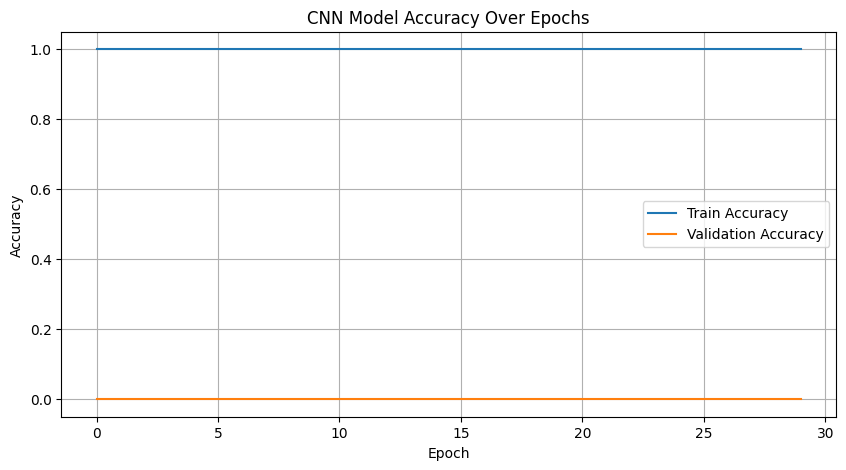

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(history_cnn.history['accuracy'], label='Train Accuracy')
plt.plot(history_cnn.history['val_accuracy'], label='Validation Accuracy')
plt.title("CNN Model Accuracy Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step


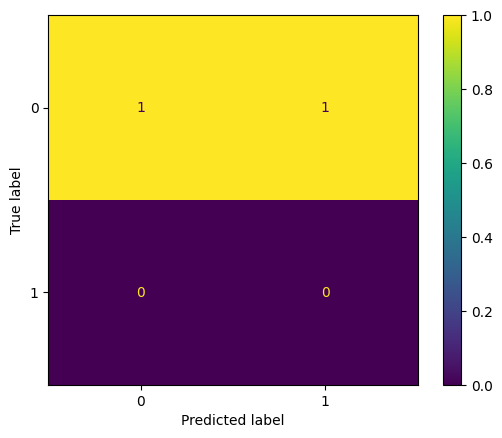

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# for the raw EEG data:
cm = confusion_matrix(y_test_raw, np.argmax(model_cnn.predict(X_test_raw), axis=1))

ConfusionMatrixDisplay(cm).plot()


# Hybrid model uing both Featured and Raw Data model Of EEG

In [ ]:
from sklearn.model_selection import train_test_split

# Create X_feat and y_feat from X and y
X_feat = X
y_feat = y

# Find common indices based on available labels in y_raw
common_indices = [i for i in range(len(y)) if i < len(y_raw)]

# Subset X, X_raw, and y to keep only common samples
X_feat = X_feat[common_indices]
X_raw = X_raw[common_indices]
y_feat = y_feat[common_indices]

# Use same split for both branches
X_train_feat, X_test_feat, X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_feat, X_raw, y_feat, test_size=0.2, random_state=42
)

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense, Dropout, Conv1D, GlobalAveragePooling1D, Concatenate
from tensorflow.keras.models import Model

# Feature Input Branch
input_feat = Input(shape=(X_train_feat.shape[1],), name='engineered_features')
x_feat = Dense(64, activation='relu')(input_feat)
x_feat = Dropout(0.3)(x_feat)

# Raw EEG Input Branch
input_raw = Input(shape=(X_train_raw.shape[1], X_train_raw.shape[2]), name='raw_eeg_input')
x_raw = Conv1D(64, kernel_size=5, activation='relu')(input_raw)
x_raw = GlobalAveragePooling1D()(x_raw)

# Merge branches
merged = Concatenate()([x_feat, x_raw])
x = Dense(64, activation='relu')(merged)
x = Dropout(0.3)(x)
output = Dense(len(np.unique(y)), activation='softmax')(x)

# Build model
hybrid_model = Model(inputs=[input_feat, input_raw], outputs=output)

# Compile
hybrid_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

hybrid_model.summary()


Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ engineered_features │ (None, 144)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ raw_eeg_input       │ (None, 20000, 22) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_25 (Dense)    │ (None, 64)        │      9,280 │ engineered_featu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_14 (Conv1D)  │ (None, 19996, 64) │      7,104 │ raw_eeg_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 64)        │          0 │ dense_25[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ conv1d_14[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 128)       │          0 │ dropout_6[0][0],  │
│ (Concatenate)       │                   │            │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_26 (Dense)    │ (None, 64)        │      8,256 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 64)        │          0 │ dense_26[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_27 (Dense)    │ (None, 5)         │        325 │ dropout_7[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 24,965 (97.52 KB)

 Trainable params: 24,965 (97.52 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = hybrid_model.fit(
    [X_train_feat, X_train_raw],
    y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=8,
    verbose=1
)


Epoch 1/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.3333 - loss: 2655.5935 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 2/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 388ms/step - accuracy: 0.3333 - loss: 2246.5476 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 3/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 300ms/step - accuracy: 0.6667 - loss: 792.9775 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 4/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 5/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step - accuracy: 0.3333 - loss: 436.2773 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 6/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 277ms/step - accuracy: 0.6667 - loss: 1213.0991 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 7/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 8/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 294ms/step - accuracy: 0.3333 - l

In [ ]:
loss, acc = hybrid_model.evaluate([X_test_feat, X_test_raw], y_test, verbose=0)
print(f" Test Accuracy (Hybrid Model): {acc:.2f}")


🔍 Test Accuracy (Hybrid Model): 0.50


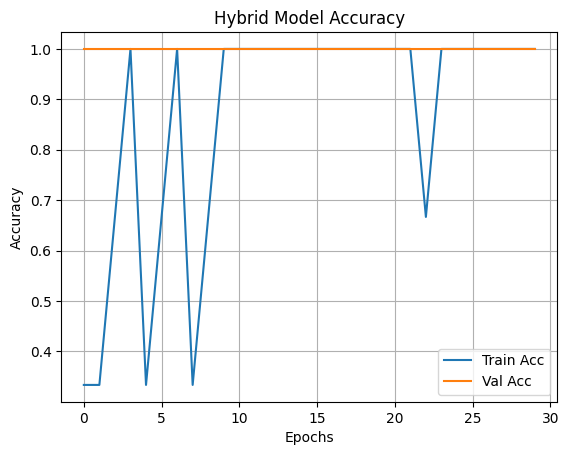

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title("Hybrid Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


✅ Accuracy: 0.5000

📄 Classification Report:
              precision    recall  f1-score   support

       Funny       1.00      0.50      0.67         2
         Sad       0.00      0.00      0.00         0

    accuracy                           0.50         2
   macro avg       0.50      0.25      0.33         2
weighted avg       1.00      0.50      0.67         2



/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


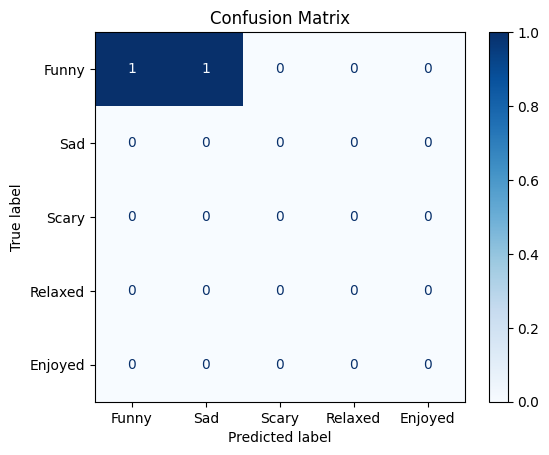

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_ranking.py:1179: UndefinedMetricWarning: No negative samples in y_true, false positive value should be meaningless
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(


<Figure size 800x600 with 0 Axes>

In [ ]:
rf_model = clf  # Assign 'clf' to 'rf_model'
class_names = [k for k, v in emotion_labels.items()]
from sklearn.model_selection import train_test_split
X_train_feat, X_test_feat, y_train_feat, y_test_feat = train_test_split(
    X_feat, y_feat, test_size=0.2, random_state=42
)

evaluate_model(rf_model, X_test_feat, y_test_feat, class_names, is_deep=False)